In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from river import datasets
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

records = [
    {**x, "target": int(y)}
    for x, y in datasets.Elec2()
]

df = pd.DataFrame(records)

FEATURES = [
    "day", "period", "nswprice", "nswdemand",
    "vicprice", "vicdemand", "transfer"
]

TRAIN_SIZE = 5000
BATCH_SIZE = 336

train = df.iloc[:TRAIN_SIZE]
stream = df.iloc[TRAIN_SIZE:]

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

model.fit(train[FEATURES], train["target"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['day','period','nswprice',...,'vicprice','vicdemand','transfer']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


,feature,coefficient,absolute_coefficient
2,nswprice,2.360312e+00,2.360312e+00
3,nswdemand,1.871600e-01,1.871600e-01
0,day,1.310047e-01,1.310047e-01
1,period,-1.038890e-02,1.038890e-02
5,vicdemand,7.091764e-17,7.091764e-17
6,transfer,2.363921e-17,2.363921e-17
4,vicprice,3.693627e-19,3.693627e-19


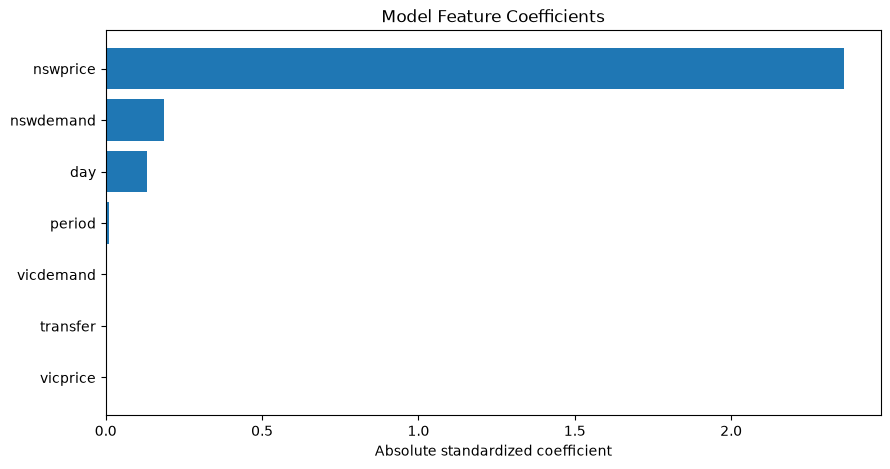

In [2]:

coefficients = model.named_steps["logisticregression"].coef_[0]

importance = pd.DataFrame({
    "feature": FEATURES,
    "coefficient": coefficients,
    "absolute_coefficient": np.abs(coefficients)
}).sort_values("absolute_coefficient", ascending=False)

display(importance)

plt.figure(figsize=(10, 5))
plt.barh(
    importance["feature"],
    importance["absolute_coefficient"]
)
plt.gca().invert_yaxis()
plt.xlabel("Absolute standardized coefficient")
plt.title("Model Feature Coefficients")
plt.show()

In [3]:

def calculate_psi(reference, current, n_bins=10):
    edges = np.quantile(
        reference,
        np.linspace(0, 1, n_bins + 1)
    )
    edges[0] = -np.inf
    edges[-1] = np.inf
    edges = np.unique(edges)

    p = np.histogram(reference, bins=edges)[0].astype(float)
    q = np.histogram(current, bins=edges)[0].astype(float)

    eps = 1e-6
    p = np.maximum(p / p.sum(), eps)
    q = np.maximum(q / q.sum(), eps)

    p /= p.sum()
    q /= q.sum()

    return np.sum((q - p) * np.log(q / p))


rows = []

for batch_id, start in enumerate(
    range(0, len(stream), BATCH_SIZE), start=1
):
    batch = stream.iloc[start:start + BATCH_SIZE]

    accuracy = accuracy_score(
        batch["target"],
        model.predict(batch[FEATURES])
    )

    for feature in FEATURES:
        psi = calculate_psi(
            train[feature].to_numpy(),
            batch[feature].to_numpy()
        )

        rows.append({
            "batch": batch_id,
            "feature": feature,
            "psi": psi,
            "accuracy": accuracy
        })

drift_df = pd.DataFrame(rows)

display(drift_df.head())

,batch,feature,psi,accuracy
0,1,day,0.000392,0.803571
1,1,period,0.000011,0.803571
2,1,nswprice,1.879167,0.803571
3,1,nswdemand,0.212547,0.803571
4,1,vicprice,0.000000,0.803571


In [4]:

results = []

for feature, group in drift_df.groupby("feature"):
    rho, p_value = spearmanr(
        group["psi"], group["accuracy"]
    )

    results.append({
        "feature": feature,
        "spearman_rho": rho,
        "p_value": p_value,
        "mean_psi": group["psi"].mean()
    })

correlations = pd.DataFrame(results)

feature_summary = correlations.merge(
    importance,
    on="feature"
).sort_values("spearman_rho")

display(feature_summary.round(4))

,feature,spearman_rho,p_value,mean_psi,coefficient,absolute_coefficient
6,vicprice,-0.5705,0.0000,8.0017,0.0000,0.0000
2,nswprice,-0.5124,0.0000,3.6172,2.3603,2.3603
5,vicdemand,-0.4409,0.0000,5.0215,0.0000,0.0000
4,transfer,-0.1043,0.2569,2.1145,0.0000,0.0000
1,nswdemand,-0.0115,0.9011,1.4295,0.1872,0.1872
0,day,0.0119,0.8973,0.0004,0.1310,0.1310
3,period,0.0119,0.8973,0.0000,-0.0104,0.0104


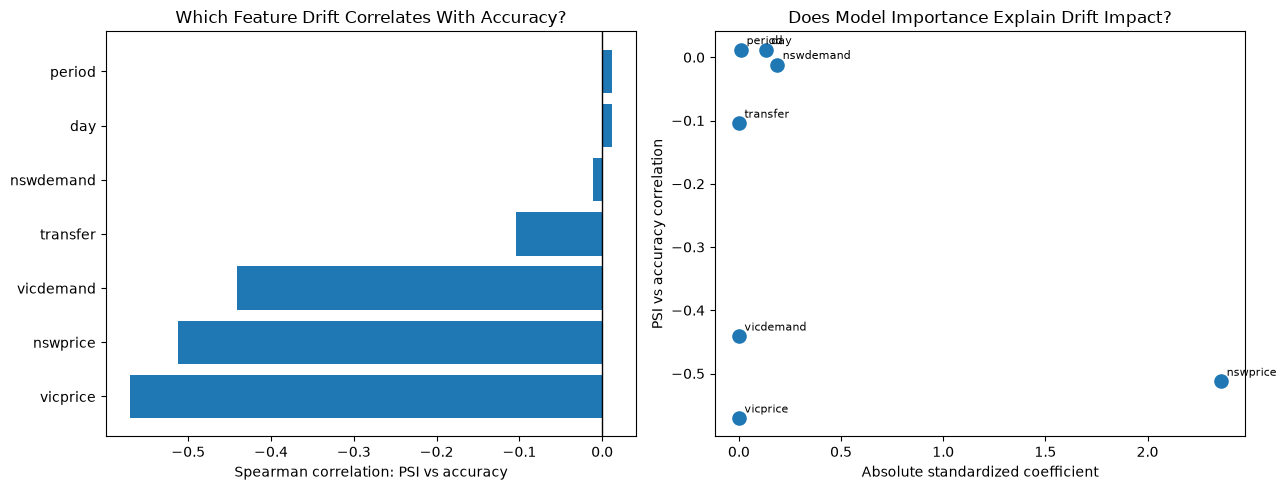

In [5]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(
    feature_summary["feature"],
    feature_summary["spearman_rho"]
)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlabel("Spearman correlation: PSI vs accuracy")
axes[0].set_title("Which Feature Drift Correlates With Accuracy?")

axes[1].scatter(
    feature_summary["absolute_coefficient"],
    feature_summary["spearman_rho"],
    s=90
)

for _, row in feature_summary.iterrows():
    axes[1].annotate(
        row["feature"],
        (row["absolute_coefficient"], row["spearman_rho"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

axes[1].set_xlabel("Absolute standardized coefficient")
axes[1].set_ylabel("PSI vs accuracy correlation")
axes[1].set_title("Does Model Importance Explain Drift Impact?")

plt.tight_layout()
plt.show()